<a href="https://colab.research.google.com/github/ambicatanmayeeyerramaneni232-dot/DuoOmic-CrossAttention-GNN/blob/main/DuoOmic_GNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Duo-Omic Cross-Attention GNN for Cholangiocarcinoma



In [ ]:
!pip install -q torch-geometric shap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.5 MB/s eta 0:00:00


In [ ]:
# ---- 1. Upload the two UCSC Xena files, ONE AT A TIME ----
# (Colab may rename a file to e.g. "HiSeqV2 (1).gz" - that is fine, the code finds it by keyword.)
import os, glob

def find_file(keyword):
    hits = sorted(glob.glob(f'*{keyword}*'))
    return hits[0] if hits else None

NEEDED = [
    ('HiSeqV2',             'RNA-seq file        -> TCGA.CHOL.sampleMap_HiSeqV2.gz'),
    ('HumanMethylation450', 'Methylation file    -> TCGA.CHOL.sampleMap_HumanMethylation450.gz'),
]

for keyword, label in NEEDED:
    if find_file(keyword) is None:
        from google.colab import files
        print(f'\nPlease upload the {label}')
        files.upload()
        if find_file(keyword) is None:
            raise FileNotFoundError(f'Could not find a file with "{keyword}" in its name. Rerun this cell and upload the {label}')
    print('Found:', find_file(keyword))

RNA_FILE  = find_file('HiSeqV2')
METH_FILE = find_file('HumanMethylation450')
print('\nRNA file:        ', RNA_FILE)
print('Methylation file:', METH_FILE)


Please upload the RNA-seq file        -> TCGA.CHOL.sampleMap_HiSeqV2.gz


Saving TCGA.CHOL.sampleMap_HiSeqV2.gz to TCGA.CHOL.sampleMap_HiSeqV2.gz
Found: TCGA.CHOL.sampleMap_HiSeqV2.gz

Please upload the Methylation file    -> TCGA.CHOL.sampleMap_HumanMethylation450.gz


Saving TCGA.CHOL.sampleMap_HumanMethylation450.gz to TCGA.CHOL.sampleMap_HumanMethylation450.gz
Found: TCGA.CHOL.sampleMap_HumanMethylation450.gz

RNA file:         TCGA.CHOL.sampleMap_HiSeqV2.gz
Methylation file: TCGA.CHOL.sampleMap_HumanMethylation450.gz


In [ ]:
# ---- 2. Load data, match patients, make labels ----
import pandas as pd
import numpy as np

rna  = pd.read_csv(RNA_FILE,  sep='\t', index_col=0).T   # samples x genes  (Xena HiSeqV2 is already log2(x+1))
meth = pd.read_csv(METH_FILE, sep='\t', index_col=0).T   # samples x CpG probes (beta values 0-1)

print('RNA-seq:     ', rna.shape,  ' e.g.', list(rna.columns[:3]))
print('Methylation: ', meth.shape, ' e.g.', list(meth.columns[:3]))

# Safety checks: the two tables must be different data types
assert rna.shape[1] != meth.shape[1], 'RNA and methylation tables have the same size - the same file was probably loaded twice.'
assert rna.columns.str.startswith('cg').mean() < 0.5, 'RNA columns look like CpG probes - wrong file loaded as RNA.'
assert meth.columns.str.startswith('cg').mean() > 0.5, 'Methylation columns do not look like CpG probes.'

common = rna.index.intersection(meth.index).sort_values()
rna, meth = rna.loc[common], meth.loc[common]

sample_type = np.array([int(str(s).split('-')[3][:2]) for s in common])
y = (sample_type < 10).astype(int)          # TCGA codes 01-09 = tumour, 10-19 = normal
print(f'\nMatched {len(common)} patients: {y.sum()} tumour | {(1 - y).sum()} non-tumour')
print('Sample type codes:', dict(zip(*np.unique(sample_type, return_counts=True))))

RNA-seq:      (45, 20530)  e.g. ['ARHGEF10L', 'HIF3A', 'RNF17']
Methylation:  (45, 485577)  e.g. ['cg13332474', 'cg00651829', 'cg17027195']

Matched 45 patients: 36 tumour | 9 non-tumour
Sample type codes: {np.int64(1): np.int64(36), np.int64(11): np.int64(9)}


In [ ]:
# ---- 3. Map CpG probes to genes and remove X/Y chromosome probes ----
PROBEMAP_URL  = 'https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/probeMap/illuminaMethyl450_hg19_GPL16304_TCGAlegacy'
PROBEMAP_FILE = 'illuminaMethyl450_hg19_GPL16304_TCGAlegacy'

BACKUP_URL    = 'https://gdc-hub.s3.us-east-1.amazonaws.com/download/HM450.hg38.manifest.gencode.v36.probeMap'

if not os.path.exists(PROBEMAP_FILE):
    import urllib.request
    for url in (PROBEMAP_URL, BACKUP_URL):
        try:
            urllib.request.urlretrieve(url, PROBEMAP_FILE)
            print('Probe map downloaded from', url)
            break
        except Exception as e:
            print('Could not download', url, '-', e)
    else:
        print('Automatic download failed.')
        print('On the UCSC Xena page for the HumanMethylation450 dataset, download the "ID/Gene Mapping" file and upload it here.')
        from google.colab import files
        up = files.upload()
        PROBEMAP_FILE = list(up.keys())[0]

pmap = pd.read_csv(PROBEMAP_FILE, sep='\t')
pmap = pmap.rename(columns={pmap.columns[0]: 'id'}).set_index('id')
cpg_to_gene  = pmap['gene'].fillna('').replace('.', '').to_dict()
cpg_to_chrom = pmap['chrom'].fillna('').to_dict()

sex_probes = [c for c in meth.columns if cpg_to_chrom.get(c, '') in ('chrX', 'chrY')]
meth = meth.drop(columns=sex_probes)
print(f'Removed {len(sex_probes)} X/Y probes. Methylation now: {meth.shape}')

Probe map downloaded from https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/probeMap/illuminaMethyl450_hg19_GPL16304_TCGAlegacy
Removed 10141 X/Y probes. Methylation now: (45, 475436)


In [ ]:
# ---- 4. Split FIRST, then fit every preprocessing step on the training samples only ----
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler

K = 30            # features kept per data type
SEED = 42

def preprocess(df, tr, te, y_tr, k=K):
    """Fit cleaning, filtering, selection and scaling on training rows only."""
    d_tr, d_te = df.iloc[tr], df.iloc[te]
    keep = d_tr.columns[d_tr.notna().mean() >= 0.9]          # drop features missing in >10% of training samples
    d_tr, d_te = d_tr[keep], d_te[keep]
    imp = SimpleImputer(strategy='median').fit(d_tr)
    X_tr, X_te = imp.transform(d_tr), imp.transform(d_te)
    vt = VarianceThreshold(0.01).fit(X_tr)
    X_tr, X_te, cols = vt.transform(X_tr), vt.transform(X_te), keep[vt.get_support()]
    kb = SelectKBest(f_classif, k=k).fit(X_tr, y_tr)
    X_tr, X_te, cols = kb.transform(X_tr), kb.transform(X_te), cols[kb.get_support()]
    sc = StandardScaler().fit(X_tr)
    return sc.transform(X_tr), sc.transform(X_te), list(cols)

idx = np.arange(len(y))
train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=SEED)   # 80:20 split, fixed seed
y_train, y_test = y[train_idx], y[test_idx]

Xr_tr, Xr_te, rna_feats  = preprocess(rna,  train_idx, test_idx, y_train)
Xm_tr, Xm_te, meth_feats = preprocess(meth, train_idx, test_idx, y_train)

print(f'Train: {len(train_idx)} ({y_train.sum()} tumour) | Test: {len(test_idx)} ({y_test.sum()} tumour)')
print('Top RNA features (genes):', rna_feats[:5])
print('Top CpG features:', meth_feats[:5])

Train: 36 (28 tumour) | Test: 9 (8 tumour)
Top RNA features (genes): ['ALAS1', 'VPS24', 'ACAA1', 'DNAJC25', 'ZGPAT']
Top CpG features: ['cg21009747', 'cg14524724', 'cg00590251', 'cg05891572', 'cg18554976']


In [ ]:
# ---- 5. Model: cross-attention fusion + GATv2 (same architecture as before) ----
import random, torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Fully connected graph: every one of the K feature nodes is linked to every other node
edge_index = torch.tensor([[i, j] for i in range(K) for j in range(K) if i != j], dtype=torch.long).t().contiguous().to(device)

class CrossAttentionFusion(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.query, self.key, self.value = nn.Linear(dim, dim), nn.Linear(dim, dim), nn.Linear(dim, dim)
    def forward(self, rna, meth):
        Q, K_, V = self.query(meth), self.key(rna), self.value(rna)      # methylation asks, RNA answers
        attn = F.softmax(Q @ K_.transpose(-1, -2) / np.sqrt(self.dim), dim=-1)
        return attn @ V + meth                                         # residual connection

class DuoOmicGNN(nn.Module):
    def __init__(self, in_dim=1, hidden_dim=16):
        super().__init__()
        self.fusion = CrossAttentionFusion(in_dim)
        self.gat1 = GATv2Conv(in_dim, hidden_dim, heads=2, concat=True)
        self.gat2 = GATv2Conv(hidden_dim * 2, hidden_dim, heads=1, concat=False)
        self.classifier = nn.Sequential(nn.Linear(hidden_dim, 16), nn.ReLU(), nn.Linear(16, 2))
    def forward(self, rna_node, meth_node, edge_index):
        x = self.fusion(rna_node, meth_node)
        x = F.elu(self.gat1(x, edge_index))
        x = F.elu(self.gat2(x, edge_index))
        return self.classifier(x.mean(dim=0, keepdim=True))

EPOCHS, LR = 20, 0.005

def to_t(row):
    return torch.tensor(row, dtype=torch.float).unsqueeze(1).to(device)

def train_model(Xr, Xm, yy, epochs=EPOCHS, lr=LR, verbose=True):
    set_seed()
    model = DuoOmicGNN().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    model.train()
    for ep in range(1, epochs + 1):
        total = 0.0
        for r, m, lab in zip(Xr, Xm, yy):
            opt.zero_grad()
            loss = loss_fn(model(to_t(r), to_t(m), edge_index), torch.tensor([lab], device=device))
            loss.backward(); opt.step(); total += loss.item()
        if verbose and ep % 5 == 0:
            print(f'Epoch {ep:02d} | training loss {total / len(yy):.4f}')
    return model

@torch.no_grad()
def predict_proba(model, Xr, Xm):
    model.eval()
    return np.array([torch.softmax(model(to_t(r), to_t(m), edge_index), dim=1)[0, 1].item() for r, m in zip(Xr, Xm)])

model = train_model(Xr_tr, Xm_tr, y_train)

Epoch 05 | training loss 0.0005
Epoch 10 | training loss 0.0001
Epoch 15 | training loss 0.0000
Epoch 20 | training loss 0.0000


In [ ]:
# ---- 6. Test-set performance with exact 95% confidence intervals ----
from sklearn.metrics import roc_auc_score, confusion_matrix
from scipy.stats import beta

def clopper_pearson(k, n, a=0.05):
    lo = beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return lo, hi

def report(y_true, probs, title):
    pred = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    auc = roc_auc_score(y_true, probs) if len(np.unique(y_true)) > 1 else float('nan')
    print(f'--- {title} ---')
    print(f'Confusion matrix: TN={tn} FP={fp} FN={fn} TP={tp}')
    for name, k, n in [('Accuracy', tp + tn, tp + tn + fp + fn), ('Sensitivity', tp, tp + fn), ('Specificity', tn, tn + fp)]:
        lo, hi = clopper_pearson(k, n)
        print(f'{name:12s} {k}/{n} = {k / n:.1%}  (95% CI {lo:.1%} - {hi:.1%})')
    print(f'ROC-AUC      {auc:.3f}')
    return pred

test_probs = predict_proba(model, Xr_te, Xm_te)
test_pred = report(y_test, test_probs, 'Held-out test set')

--- Held-out test set ---
Confusion matrix: TN=1 FP=0 FN=1 TP=7
Accuracy     8/9 = 88.9%  (95% CI 51.8% - 99.7%)
Sensitivity  7/8 = 87.5%  (95% CI 47.3% - 99.7%)
Specificity  1/1 = 100.0%  (95% CI 2.5% - 100.0%)
ROC-AUC      1.000


In [ ]:
# ---- 7. Robustness check: stratified 5-fold cross-validation over all patients ----
from sklearn.model_selection import StratifiedKFold

oof = np.zeros(len(y))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (tr, te) in enumerate(skf.split(idx, y), 1):
    a_tr, a_te, _ = preprocess(rna,  tr, te, y[tr])
    b_tr, b_te, _ = preprocess(meth, tr, te, y[tr])
    m = train_model(a_tr, b_tr, y[tr], verbose=False)
    oof[te] = predict_proba(m, a_te, b_te)
    print(f'Fold {fold}: {len(te)} test samples ({(1 - y[te]).sum()} non-tumour)')
_ = report(y, oof, 'Out-of-fold predictions, all patients (5-fold CV)')

Fold 1: 9 test samples (1 non-tumour)
Fold 2: 9 test samples (2 non-tumour)
Fold 3: 9 test samples (2 non-tumour)
Fold 4: 9 test samples (2 non-tumour)
Fold 5: 9 test samples (2 non-tumour)
--- Out-of-fold predictions, all patients (5-fold CV) ---
Confusion matrix: TN=9 FP=0 FN=2 TP=34
Accuracy     43/45 = 95.6%  (95% CI 84.9% - 99.5%)
Sensitivity  34/36 = 94.4%  (95% CI 81.3% - 99.3%)
Specificity  9/9 = 100.0%  (95% CI 66.4% - 100.0%)
ROC-AUC      1.000


In [ ]:
# ---- 8. SHAP: which inputs did the model rely on? ----
import shap

feat_names = [f'RNA:{g}' for g in rna_feats] + [f'METH:{c}' for c in meth_feats]

def shap_predict(flat):
    return predict_proba(model, flat[:, :K], flat[:, K:])

X_tr_flat = np.hstack([Xr_tr, Xm_tr])
X_te_flat = np.hstack([Xr_te, Xm_te])
background = shap.kmeans(X_tr_flat, 5)                # 5-point summary of the TRAINING data
explainer = shap.KernelExplainer(shap_predict, background)
shap_values = explainer.shap_values(X_te_flat, nsamples=500)

mean_abs = np.abs(np.array(shap_values)).mean(axis=0)
order = np.argsort(mean_abs)[::-1]
ranking = pd.DataFrame({
    'Rank': np.arange(1, len(order) + 1),
    'Feature': [feat_names[i].split(':', 1)[1] for i in order],
    'Omic_Type': ['Transcriptomic (RNA)' if feat_names[i].startswith('RNA') else 'Epigenomic (CpG)' for i in order],
    'SHAP_Importance': mean_abs[order],
})
ranking['Gene'] = [f if t.startswith('Trans') else (cpg_to_gene.get(f, '') or 'no annotated gene')
                   for f, t in zip(ranking['Feature'], ranking['Omic_Type'])]
ranking.to_csv('shap_ranking_all_features.csv', index=False)
top10 = ranking.head(10)
print(top10.to_string(index=False))

  0%|          | 0/9 [00:00<?, ?it/s]

 Rank    Feature        Omic_Type  SHAP_Importance                                   Gene
    1 cg07621758 Epigenomic (CpG)         0.034986                                MICALL1
    2 cg26495393 Epigenomic (CpG)         0.025606                                  ARMC5
    3 cg21864730 Epigenomic (CpG)         0.021768             NDUFC2-KCTD14,THRSP,KCTD14
    4 cg16161418 Epigenomic (CpG)         0.021108                                PPP1R18
    5 cg18554976 Epigenomic (CpG)         0.017865 LGI4,FXYD1,CTD-2527I21.5,CTD-2527I21.4
    6 cg07573965 Epigenomic (CpG)         0.017210                                 HMGXB4
    7 cg03956606 Epigenomic (CpG)         0.016762                           ANGPTL7,MTOR
    8 cg19525780 Epigenomic (CpG)         0.013595                               C14orf80
    9 cg00590251 Epigenomic (CpG)         0.013012                                 STEAP3
   10 cg14524724 Epigenomic (CpG)         0.012663                      no annotated gene


In [ ]:
# ---- 9. KEGG pathway enrichment with the Enrichr API ----
import requests

TOP_N = 10        # genes taken from the top-N SHAP features
genes = []
for g in ranking.head(TOP_N)['Gene']:
    for part in str(g).replace(';', ',').split(','):
        part = part.strip()
        if part and part != 'no annotated gene' and part not in genes:
            genes.append(part)
print('Genes sent to Enrichr:', genes)

ENRICHR = 'https://maayanlab.cloud/Enrichr'
r = requests.post(f'{ENRICHR}/addList', files={'list': (None, '\n'.join(genes)), 'description': (None, 'CCA top SHAP genes')})
r.raise_for_status()
user_list_id = r.json()['userListId']
r = requests.get(f'{ENRICHR}/enrich', params={'userListId': user_list_id, 'backgroundType': 'KEGG_2021_Human'})
r.raise_for_status()
rows = r.json()['KEGG_2021_Human']
kegg = pd.DataFrame([{'Pathway': x[1], 'P_value': x[2], 'Adjusted_P_value': x[6], 'Overlapping_genes': ', '.join(x[5])} for x in rows])
kegg.to_csv('kegg_enrichment.csv', index=False)
print(kegg.head(10).to_string(index=False))
print('\nPathways with adjusted p < 0.05:', int((kegg['Adjusted_P_value'] < 0.05).sum()))

Genes sent to Enrichr: ['MICALL1', 'ARMC5', 'NDUFC2-KCTD14', 'THRSP', 'KCTD14', 'PPP1R18', 'LGI4', 'FXYD1', 'CTD-2527I21.5', 'CTD-2527I21.4', 'HMGXB4', 'ANGPTL7', 'MTOR', 'C14orf80', 'STEAP3']
                        Pathway  P_value  Adjusted_P_value   Overlapping_genes
        Diabetic cardiomyopathy 0.009868          0.159182 NDUFC2-KCTD14, MTOR
                  Thermogenesis 0.012736          0.159182 NDUFC2-KCTD14, MTOR
             Huntington disease 0.021483          0.159182 NDUFC2-KCTD14, MTOR
  Amyotrophic lateral sclerosis 0.029664          0.159182 NDUFC2-KCTD14, MTOR
                    Ferroptosis 0.030323          0.159182              STEAP3
              Alzheimer disease 0.030420          0.159182 NDUFC2-KCTD14, MTOR
      Type II diabetes mellitus 0.033962          0.159182                MTOR
  Pathways of neurodegeneration 0.048191          0.159182 NDUFC2-KCTD14, MTOR
         Acute myeloid leukemia 0.049105          0.159182                MTOR
Adipocytokine sig

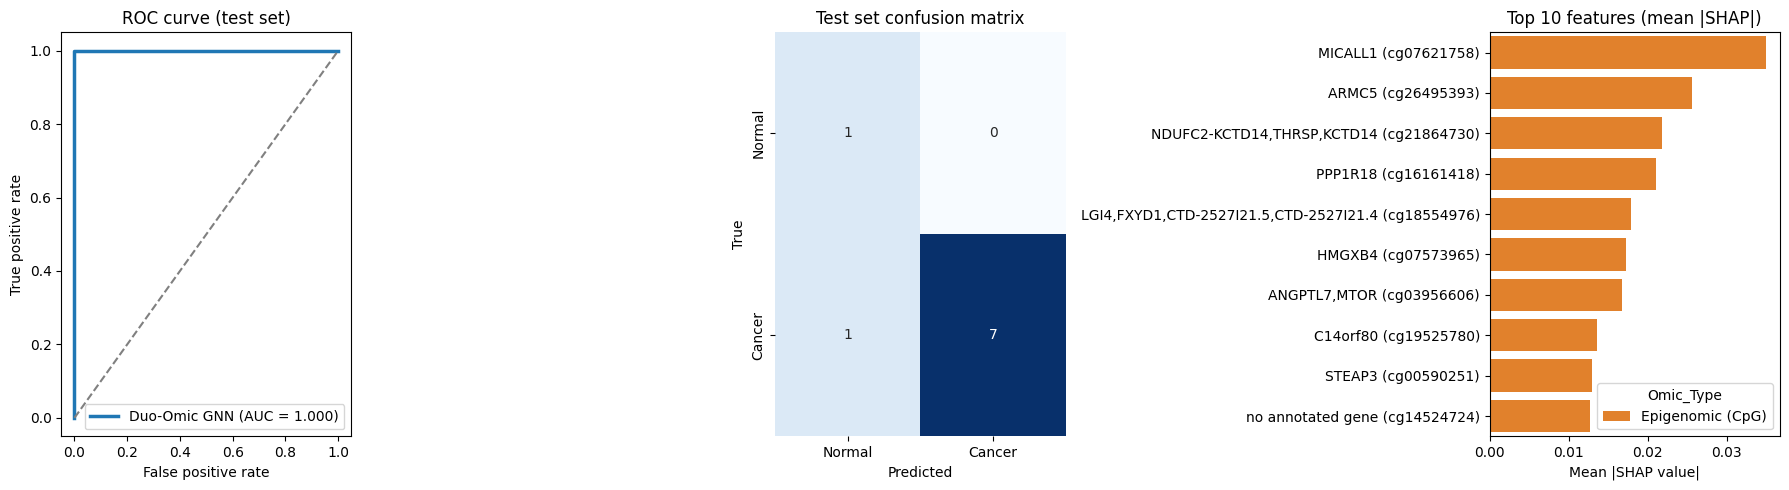

Samples: 45 (36 tumour, 9 non-tumour)
RNA genes: 20530, CpG probes after X/Y removal: 475436, features per type: 30
Train 36 / Test 9, epochs 20, lr 0.005
Test AUC: 1.000, CV out-of-fold AUC: 1.000

 Rank    Feature        Omic_Type  SHAP_Importance                                   Gene
    1 cg07621758 Epigenomic (CpG)         0.034986                                MICALL1
    2 cg26495393 Epigenomic (CpG)         0.025606                                  ARMC5
    3 cg21864730 Epigenomic (CpG)         0.021768             NDUFC2-KCTD14,THRSP,KCTD14
    4 cg16161418 Epigenomic (CpG)         0.021108                                PPP1R18
    5 cg18554976 Epigenomic (CpG)         0.017865 LGI4,FXYD1,CTD-2527I21.5,CTD-2527I21.4
    6 cg07573965 Epigenomic (CpG)         0.017210                                 HMGXB4
    7 cg03956606 Epigenomic (CpG)         0.016762                           ANGPTL7,MTOR
    8 cg19525780 Epigenomic (CpG)         0.013595                               

In [ ]:
# ---- 10. Figures and a summary to copy into the paper ----
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc as sk_auc

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fpr, tpr, _ = roc_curve(y_test, test_probs)
axes[0].plot(fpr, tpr, lw=2.5, label=f'Duo-Omic GNN (AUC = {sk_auc(fpr, tpr):.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='ROC curve (test set)', xlabel='False positive rate', ylabel='True positive rate'); axes[0].legend(loc='lower right')

sns.heatmap(confusion_matrix(y_test, test_pred, labels=[0, 1]), annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Normal', 'Cancer'], yticklabels=['Normal', 'Cancer'], ax=axes[1])
axes[1].set(title='Test set confusion matrix', xlabel='Predicted', ylabel='True')

plot_df = top10.assign(Label=[f'{g} ({f})' if t.startswith('Epi') else g for g, f, t in zip(top10['Gene'], top10['Feature'], top10['Omic_Type'])])
sns.barplot(data=plot_df, x='SHAP_Importance', y='Label', hue='Omic_Type', dodge=False,
            palette={'Epigenomic (CpG)': '#ff7f0e', 'Transcriptomic (RNA)': '#2ca02c'}, ax=axes[2])
axes[2].set(title='Top 10 features (mean |SHAP|)', xlabel='Mean |SHAP value|', ylabel='')
plt.tight_layout(); plt.savefig('DuoOmic_GNN_Results_v2.png', dpi=300, bbox_inches='tight'); plt.show()

with open('results_summary.txt', 'w') as fh:
    fh.write(f'Samples: {len(y)} ({y.sum()} tumour, {(1-y).sum()} non-tumour)\n')
    fh.write(f'RNA genes: {rna.shape[1]}, CpG probes after X/Y removal: {meth.shape[1]}, features per type: {K}\n')
    fh.write(f'Train {len(train_idx)} / Test {len(test_idx)}, epochs {EPOCHS}, lr {LR}\n')
    fh.write(f'Test AUC: {roc_auc_score(y_test, test_probs):.3f}, CV out-of-fold AUC: {roc_auc_score(y, oof):.3f}\n\n')
    fh.write(top10.to_string(index=False) + '\n\n' + kegg.head(10).to_string(index=False) + '\n')
print(open('results_summary.txt').read())
print('Download results_summary.txt, shap_ranking_all_features.csv, kegg_enrichment.csv and DuoOmic_GNN_Results_v2.png from the Files panel.')